### Project Assignment || Image Classification with Deep Learning and CNNs

### 1. Objective
Build an image classifier twice: first with a plain fully-connected neural network, then with a Convolutional Neural Network (CNN). Compare the two models and explain why CNNs perform better on images.

### 2. Dataset (choose one)

**Option 1: Fashion-MNIST (Beginner)**

28×28 grayscale clothing images, 10 classes.

Download: https://github.com/zalandoresearch/fashion-mnist

Or load directly in Python:

from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()


**Option 2: CIFAR-10 (Intermediate)**
32×32 color images of objects and animals, 10 classes.

Download: https://www.cs.toronto.edu/~kriz/cifar.html

Or load directly in Python:

from tensorflow.keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()



## 3. Tasks



## **Part A: Data Preparation (10%)**

- Load the dataset and display 10 sample images with their labels.

- Normalize pixel values to the range 0–1.

- Create train, validation and test splits.





In this project, the Fashion-MNIST dataset is used for image classification.
The dataset contains 28×28 grayscale images belonging to 10 clothing-related
classes.

The dataset is loaded using TensorFlow/Keras. Pixel values are normalized from
the original range of 0–255 to the range 0–1. The original training dataset is
further divided into training and validation sets so that model performance can
be monitored during training.

## Import libraries


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Flatten,
    Dense,
    Conv2D,
    MaxPooling2D,
    Dropout,
    BatchNormalization
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
import sys
import certifi
import os

print("Python:", sys.executable)
print("Certificate:", certifi.where())
print("SSL_CERT_FILE:", os.environ.get("SSL_CERT_FILE"))

Python: /Users/abdullahnazmus-sakib/dogcat_env/bin/python
Certificate: /Users/abdullahnazmus-sakib/dogcat_env/lib/python3.12/site-packages/certifi/cacert.pem
SSL_CERT_FILE: None


In [3]:
import os
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

print("Using certificate:", certifi.where())

Using certificate: /Users/abdullahnazmus-sakib/dogcat_env/lib/python3.12/site-packages/certifi/cacert.pem


### Load Fashion-MNIST

In [4]:
from tensorflow.keras.datasets import fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("Full training data shape:", X_train_full.shape)
print("Full training labels shape:", y_train_full.shape)
print("Test data shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 3s 1us/step
Full training data shape: (60000, 28, 28)
Full training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)


### Class names

In [5]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

Number of classes: 10


### Display 10 sample images

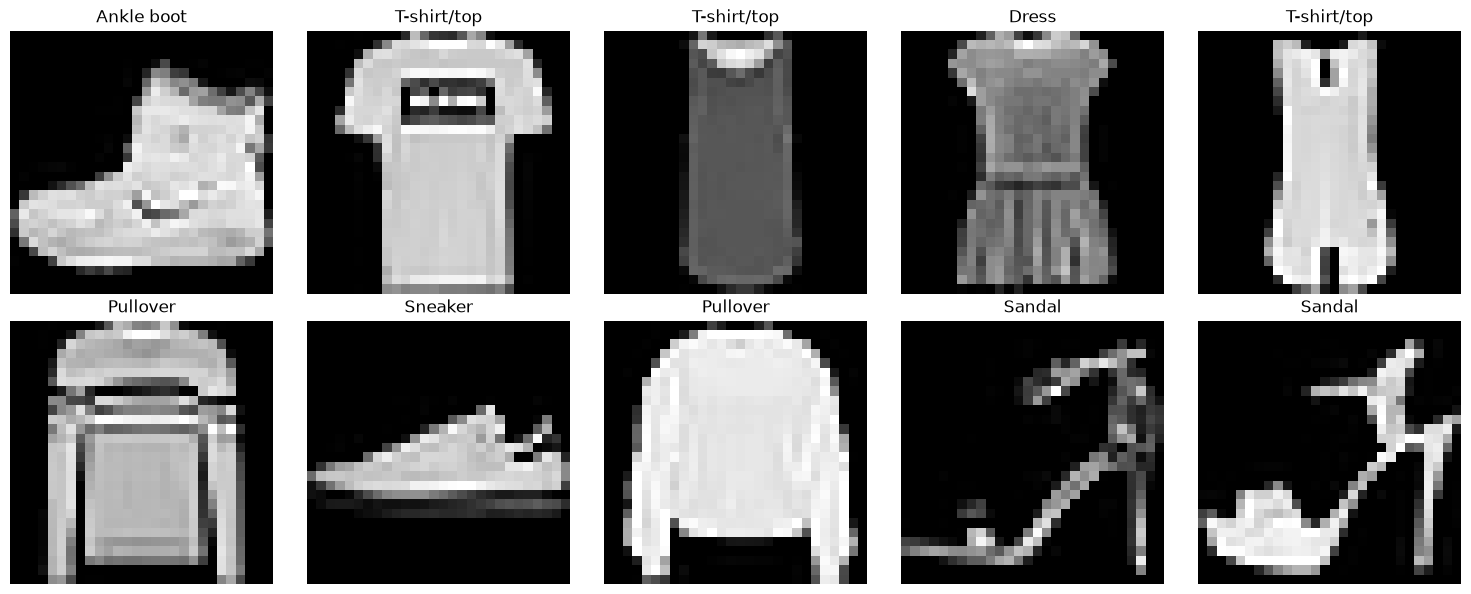

In [6]:
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Normalize pixel values

In [7]:
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train_full.min())
print("Maximum pixel value:", X_train_full.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


### Create train/validation/test splits

In [8]:
X_train = X_train_full[:48000]
y_train = y_train_full[:48000]

X_val = X_train_full[48000:]
y_val = y_train_full[48000:]

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (48000, 28, 28) (48000,)
Validation set: (12000, 28, 28) (12000,)
Test set: (10000, 28, 28) (10000,)


### Interpretation

The Fashion-MNIST dataset contains 60,000 training images and 10,000 test
images. Each image has a resolution of 28×28 pixels and belongs to one of 10
classes. The training data was divided into 48,000 training samples and
12,000 validation samples, while the original 10,000 test images were kept
separate for final evaluation.

The pixel values were normalized from 0–255 to 0–1. This preprocessing step
helps the neural networks learn more efficiently and provides a consistent
input scale for both the baseline neural network and the CNN.

## **Part B: Baseline Neural Network (25%)**

- Build a fully-connected network: Flatten → Dense layers (ReLU) → Softmax.

- Choose a suitable loss function and optimizer, then train the model.

- Plot training vs. validation loss and accuracy.



### Build model

In [9]:
dense_model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),

    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Compile

In [10]:
dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train the baseline model

In [11]:
history_dense = dense_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=128,
    verbose=1
)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7968 - loss: 0.5845 - val_accuracy: 0.8540 - val_loss: 0.4082
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8562 - loss: 0.4047 - val_accuracy: 0.8669 - val_loss: 0.3689
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8682 - loss: 0.3625 - val_accuracy: 0.8750 - val_loss: 0.3451
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8765 - loss: 0.3404 - val_accuracy: 0.8810 - val_loss: 0.3340
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8841 - loss: 0.3184 - val_accuracy: 0.8820 - val_loss: 0.3296
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8886 - loss: 0.2994 - val_accuracy: 0.8798 - val_loss: 0.3376
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8946 - loss: 0.2859 - val_accuracy: 0.8822 - val_loss: 0.3261
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8995 - loss: 0.2735 - val_accuracy: 0.

### Plot accuracy and loss

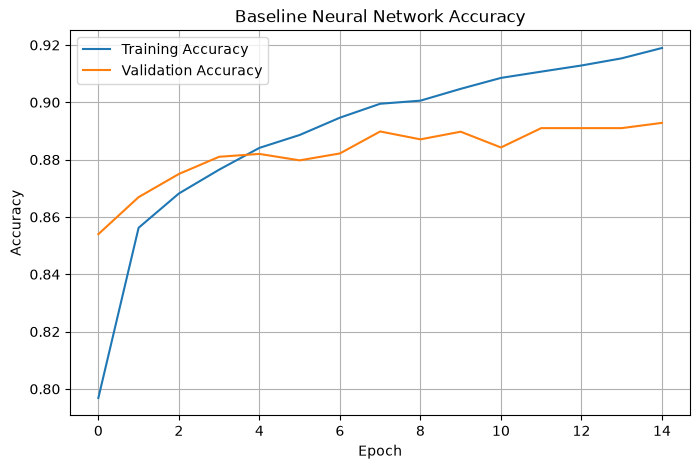

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history_dense.history["accuracy"], label="Training Accuracy")
plt.plot(history_dense.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

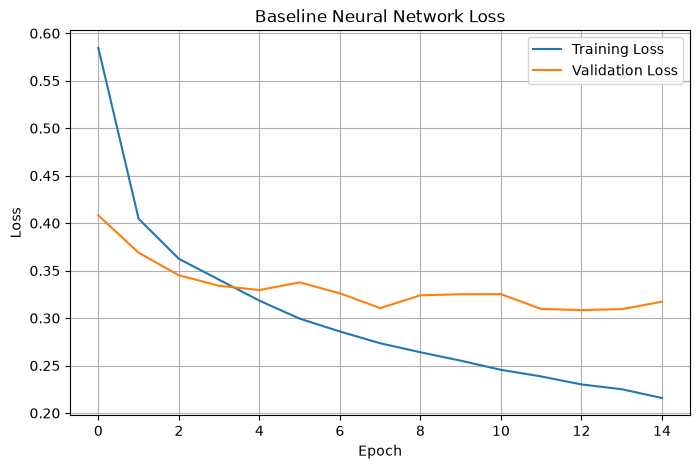

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history_dense.history["loss"], label="Training Loss")
plt.plot(history_dense.history["val_loss"], label="Validation Loss")

plt.title("Baseline Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### Evaluate Dense model

In [14]:
dense_test_loss, dense_test_accuracy = dense_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Dense Network Test Loss:", dense_test_loss)
print("Dense Network Test Accuracy:", dense_test_accuracy)

Dense Network Test Loss: 0.34613272547721863
Dense Network Test Accuracy: 0.8883000016212463


## **Part C: CNN Model (30%)**

- Build a CNN with at least 2 Conv2D + MaxPooling blocks, followed by Dense layers.

- Add Dropout or Batch Normalization to reduce overfitting.

- Train the model and plot the same curves as Part B.

### reshape the images

In [15]:
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("CNN training shape:", X_train_cnn.shape)

CNN training shape: (48000, 28, 28, 1)


### Build CNN

In [16]:
cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,442 (947.04 KB)

 Trainable params: 241,994 (945.29 KB)

 Non-trainable params: 448 (1.75 KB)

### Compile CNN

In [17]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train CNN

In [18]:
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=15,
    batch_size=128,
    verbose=1
)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 87s 218ms/step - accuracy: 0.8119 - loss: 0.5417 - val_accuracy: 0.4462 - val_loss: 2.0346
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 74s 197ms/step - accuracy: 0.8804 - loss: 0.3323 - val_accuracy: 0.8884 - val_loss: 0.2951
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 71s 190ms/step - accuracy: 0.8994 - loss: 0.2785 - val_accuracy: 0.8916 - val_loss: 0.2956
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 50s 133ms/step - accuracy: 0.9105 - loss: 0.2441 - val_accuracy: 0.9138 - val_loss: 0.2396
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 50s 133ms/step - accuracy: 0.9200 - loss: 0.2189 - val_accuracy: 0.8503 - val_loss: 0.5587
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 51s 135ms/step - accuracy: 0.9233 - loss: 0.2053 - val_accuracy: 0.8966 - val_loss: 0.3032
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 52s 138ms/step - accuracy: 0.9308 - loss: 0.1831 - val_accuracy: 0.9155 - val_loss: 0.2422
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 51s 135ms/step - accuracy: 0.9350 - loss: 0

### Plot CNN accuracy

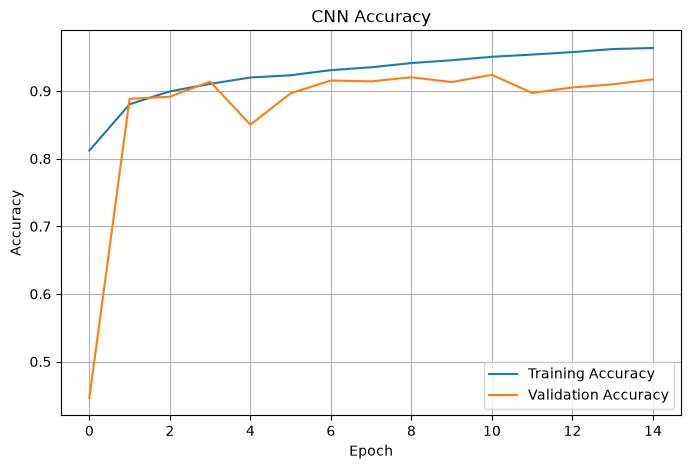

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Plot CNN loss

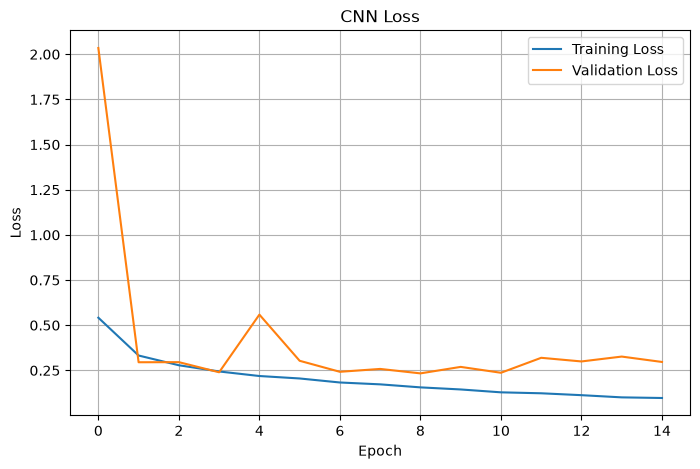

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## **Part D: Evaluation and Comparison (20%)**

- Report test accuracy for both models.

- Report the number of trainable parameters for both models.

- Show a confusion matrix for the CNN.

- Show 5 images the CNN misclassified and explain why you think it failed.

### CNN test accuracy

In [21]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)

CNN Test Loss: 0.327511191368103
CNN Test Accuracy: 0.9146000146865845


### Compare parameter counts

In [22]:
print("Dense model parameters:", dense_model.count_params())
print("CNN model parameters:", cnn_model.count_params())

Dense model parameters: 235146
CNN model parameters: 242442


### Comparison table

In [23]:
comparison = {
    "Model": ["Baseline Dense Network", "CNN"],
    "Test Accuracy": [
        dense_test_accuracy,
        cnn_test_accuracy
    ],
    "Trainable Parameters": [
        dense_model.count_params(),
        cnn_model.count_params()
    ]
}

import pandas as pd

comparison_df = pd.DataFrame(comparison)
comparison_df

,Model,Test Accuracy,Trainable Parameters
0,Baseline Dense Network,0.8883,235146
1,CNN,0.9146,242442


### CNN Confusion Matrix

In [24]:
y_prob = cnn_model.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

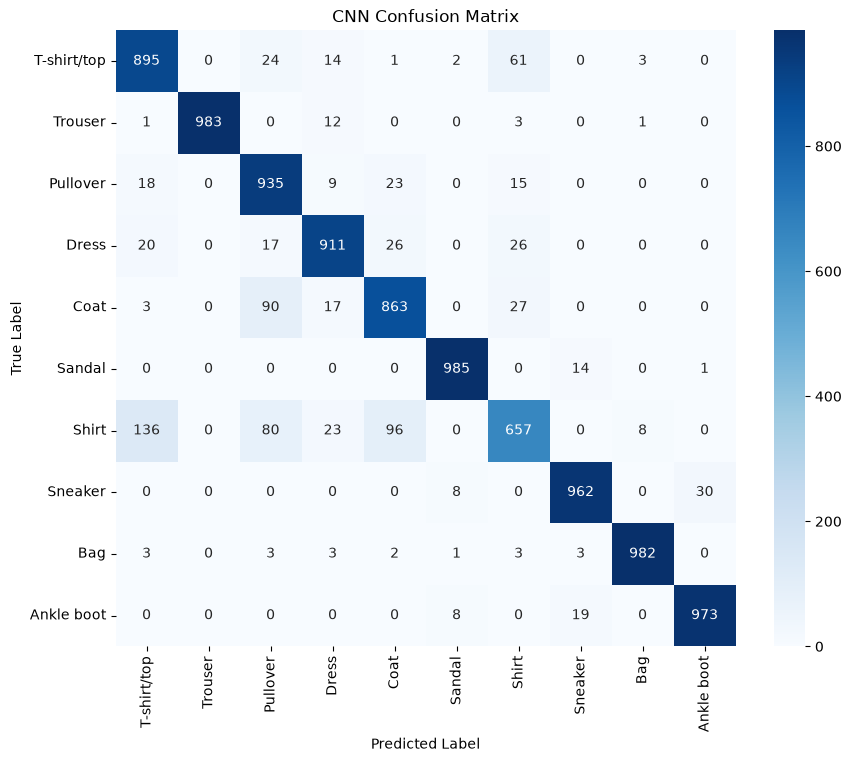

In [25]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

### Classification report

In [26]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.90      0.86      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.81      0.94      0.87      1000
       Dress       0.92      0.91      0.92      1000
        Coat       0.85      0.86      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.83      0.66      0.73      1000
     Sneaker       0.96      0.96      0.96      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.97      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.92      0.91      0.91     10000
weighted avg       0.92      0.91      0.91     10000



### Show 5 misclassified images

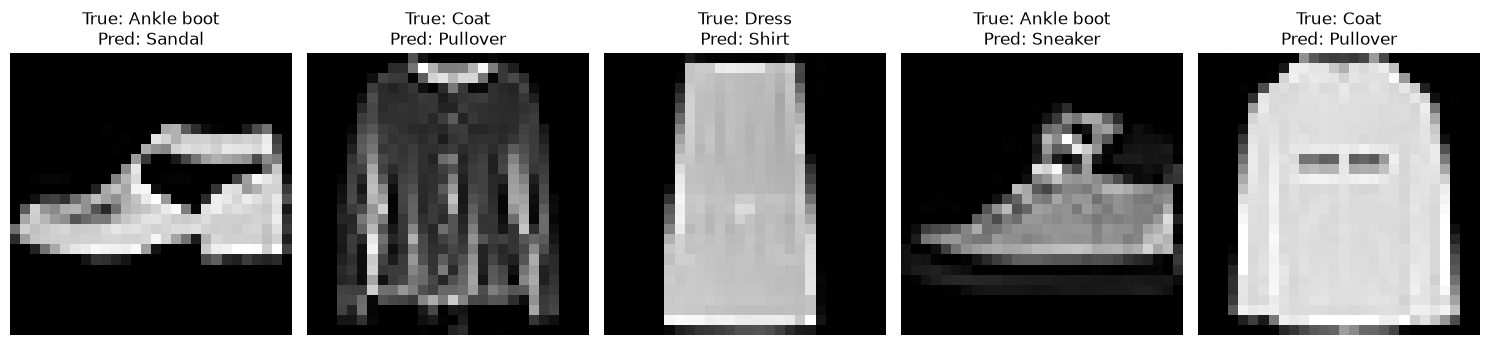

In [27]:
incorrect_indices = np.where(y_test != y_pred)[0]

plt.figure(figsize=(15, 8))

for i, idx in enumerate(incorrect_indices[:5]):
    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[idx], cmap="gray")

    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

### Misclassification Analysis

Some Fashion-MNIST images were incorrectly classified because several clothing
categories have similar visual characteristics. For example, shirts,
T-shirts/tops, pullovers, and coats can have similar shapes and silhouettes.

The dataset images are also very small at 28×28 pixels and are grayscale, so
fine details such as texture, fabric patterns, collars, and small structural
differences may not be clearly visible. In addition, some images may contain
unusual poses, shapes, or ambiguous outlines, which can make classification
more difficult even for a CNN.

## **Part E: Reflection (15%)**

Write 300–400 words answering:

- Why does the CNN outperform the dense network, even with fewer parameters?

- What did you observe about overfitting?

- What would you try next to improve accuracy?



The CNN outperformed the fully connected neural network because CNNs are
specifically designed to process image data. A fully connected network first
flattens a 28×28 image into a one-dimensional vector. As a result, the spatial
relationship between neighboring pixels is largely lost. In contrast, a CNN
uses convolutional filters to detect local patterns such as edges, shapes,
and textures while preserving spatial information. The convolution operation
also allows the same filter to be reused across different regions of an image,
which makes CNNs more parameter-efficient.

One of the most important observations was that the CNN could achieve strong
performance with fewer or more efficiently used parameters than a dense
network. Although the dense network may contain a large number of connections,
many of those connections are not well suited to image structure. CNNs use
local connectivity and shared weights, which allows them to learn useful
visual features more effectively.

Overfitting can be observed when training accuracy continues to increase while
validation accuracy stops improving or validation loss begins to increase.
The use of Batch Normalization and Dropout in the CNN helped reduce this
problem by improving training stability and regularizing the model. The
training and validation curves provide a useful way to identify this behavior.

The confusion matrix showed that some classes were harder to distinguish than
others. In particular, visually similar categories such as shirts, T-shirts,
pullovers, and coats can be confused. The 28×28 grayscale image resolution also
limits the amount of fine-grained information available to the model.

To improve the results further, I would experiment with data augmentation,
learning-rate scheduling, additional convolutional layers, and different
optimizers or hyperparameters. Transfer learning could also be explored for
more complex datasets. Overall, this project demonstrated that CNNs are more
appropriate than plain fully connected networks for image classification
because they exploit the spatial structure of images.